<a href="https://colab.research.google.com/github/Aina605/kutu-beras-akustik/blob/main/KutuBeras_Minggu1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Menyambungkan Google Drive**
Supaya Colab bisa membaca data dan menyimpan hasil di folder proyek_kutu.

In [2]:
!ls "/content/drive/MyDrive/proyek_kutu/data"

Insect-Pest-Sounds-inventory_1.csv  InsectSounds_2.zip


In [3]:
!mkdir -p /content/bugbytes
!unzip -q "/content/drive/MyDrive/proyek_kutu/data/InsectSounds_2.zip" -d /content/bugbytes
!ls /content/bugbytes | head

A10-ptr-l-m4r2f4-2s.wav
A11-ptr_adu1-72s.wav
A12-roachmoves_m54524.wav
A1-dfaccs11.wav
A2-piezimm1.wav
A3-pvdfrw1.wav
A4-accelrw.wav
A5-w40khzrw1.wav
A6-w30khzrw1.wav
A7-piezorw1.wav


**Ekstrak data Bug Bytes (USDA)**
File InsectSounds_2.zip diekstrak ke /content/bugbytes. Hasilnya 95 file WAV rekaman suara serangga hama gudang.

In [4]:
import pandas as pd
from pathlib import Path

df = pd.read_csv("/content/drive/MyDrive/proyek_kutu/data/Insect-Pest-Sounds-inventory_1.csv")
print(df.shape)
print(df.columns.tolist())
print(df.head(10).to_string())

wavs = sorted(Path("/content/bugbytes").rglob("*.wav"))
print(len(wavs), "file WAV")

(95, 3)
['Category', 'File ID', 'Description']
                                                                                                     Category File ID                                                                                                         Description
0  A.  Stored Product Insect movement and feeding sounds recorded for insect detection and monitoring studies     A.1            Plodia interpunctella larvae in dry dog food [1147 kb, 30 s] recorded with Bruel and Kjaer accelerometer
1  A.  Stored Product Insect movement and feeding sounds recorded for insect detection and monitoring studies     A.2       Individual Plodia interpunctella larva in dry dog food [489 kB, 10 s] recorded with piezoelectric disk sensor
2  A.  Stored Product Insect movement and feeding sounds recorded for insect detection and monitoring studies     A.3               Sitophilus oryzae larvae (17-18 d old) in wheat kernels [489 kB, 10 s] recorded with PVDF film sensor
3  A.  Stored Pro

**Membaca CSV inventaris**
CSV berisi 95 baris (kolom: Category, File ID, Description), jumlahnya sama dengan 95 file WAV. Dari deskripsi ini kita tahu spesies dan sensor tiap file: S. oryzae = A.3 sampai A.7, S. zeamais = A.8 dan A.9.

In [5]:
# ringkasan kategori
print(df.groupby("Category").size())

# cari file noise
noise = df[df["Description"].str.contains("noise|background|ambient", case=False, na=False)]
print(noise[["File ID", "Description"]].to_string())

# daftar target utama
oryzae = df[df["Description"].str.contains("Sitophilus oryzae", case=False, na=False)]
zeamais = df[df["Description"].str.contains("Sitophilus zeamais", case=False, na=False)]
print(oryzae[["File ID", "Description"]].to_string())
print(zeamais[["File ID", "Description"]].to_string())

Category
A.  Stored Product Insect movement and feeding sounds recorded for insect detection and monitoring studies     8
A. Stored Product Insect movement and feeding sounds recorded for insect detection and monitoring studies      4
B. Movement and feeding sounds of soil invertebrates                                                          18
C. Defensive stridulation of soil insects (dung beetles)                                                       2
D. Movement and feeding sounds of insects in wood                                                             21
E. Movement and feeding sounds of insects in plants                                                            1
F. Wing and abdominal vibration sounds recorded in insect communication studies                               28
G. Ants moving and stridulating, phorid flies, and their interaction                                           5
H. Crickets, katydids, and cicadas                                                     

**Mencari file target dan file noise dari CSV**
Kode menyaring deskripsi CSV: S. oryzae = A.3 sampai A.7 (5 sensor), S. zeamais = A.8 dan A.9. File noise ada di Kategori I (I.1 sampai I.7). I.1 dan I.2 berisi serangga bercampur suara pesawat, jadi tidak dipakai sebagai noise murni.

In [7]:
import soundfile as sf
import librosa
import pandas as pd
from scipy.io import wavfile

def get_info(p):
    # 1) soundfile
    try:
        i = sf.info(p)
        return i.samplerate, i.duration, i.channels, "soundfile"
    except Exception:
        pass
    # 2) scipy
    try:
        fs, data = wavfile.read(p)
        ch = 1 if data.ndim == 1 else data.shape[1]
        return fs, len(data) / fs, ch, "scipy"
    except Exception:
        pass
    # 3) librosa
    try:
        y, fs = librosa.load(p, sr=None, mono=False)
        ch = 1 if y.ndim == 1 else y.shape[0]
        n = y.shape[-1]
        return fs, n / fs, ch, "librosa"
    except Exception as e:
        return None, None, None, f"GAGAL: {type(e).__name__}"

rows = []
for p in wavs:
    fs, dur, ch, via = get_info(p)
    rows.append(dict(file=p.name, fs=fs,
                     durasi_s=None if dur is None else round(dur, 2),
                     channels=ch, dibaca_via=via))

inv = pd.DataFrame(rows)
inv.to_csv("/content/drive/MyDrive/proyek_kutu/data/inventaris_fs.csv", index=False)

print(inv.dibaca_via.value_counts())
print(inv.fs.value_counts(dropna=False))
print(inv.head(15).to_string())

dibaca_via
soundfile    62
scipy        33
Name: count, dtype: int64
fs
25000    59
44100    20
20000     4
50000     4
16000     3
48000     2
10000     1
24000     1
22050     1
Name: count, dtype: int64
                         file     fs  durasi_s  channels dibaca_via
0             A1-dfaccs11.wav  25000     30.00         1      scipy
1     A10-ptr-l-m4r2f4-2s.wav  20000     18.59         1  soundfile
2        A11-ptr_adu1-72s.wav  20000     21.04         1  soundfile
3   A12-roachmoves_m54524.wav  10000     35.38         1  soundfile
4             A2-piezimm1.wav  25000     10.00         1      scipy
5              A3-pvdfrw1.wav  25000     10.00         1      scipy
6              A4-accelrw.wav  25000     10.00         1      scipy
7            A5-w40khzrw1.wav  50000     10.00         1      scipy
8            A6-w30khzrw1.wav  50000     10.00         1      scipy
9             A7-piezorw1.wav  25000     10.00         1      scipy
10      A8-sz-lm3r1_f3-0s.wav  20000     20.91

**Inventaris sample rate (fs) semua file**
Semua 95 file terbaca (62 lewat soundfile, 33 lewat scipy karena header WAV-nya tidak standar). fs-nya beragam, paling banyak 25.000 Hz. Tabel disimpan sebagai inventaris_fs.csv. Ini bukti komponen A: fs tiap file tercatat.

In [8]:
print(df.groupby("Category").size())

noise = df[df["Description"].str.contains("noise|background|ambient", case=False, na=False)]
print(noise[["File ID", "Description"]].to_string())

Category
A.  Stored Product Insect movement and feeding sounds recorded for insect detection and monitoring studies     8
A. Stored Product Insect movement and feeding sounds recorded for insect detection and monitoring studies      4
B. Movement and feeding sounds of soil invertebrates                                                          18
C. Defensive stridulation of soil insects (dung beetles)                                                       2
D. Movement and feeding sounds of insects in wood                                                             21
E. Movement and feeding sounds of insects in plants                                                            1
F. Wing and abdominal vibration sounds recorded in insect communication studies                               28
G. Ants moving and stridulating, phorid flies, and their interaction                                           5
H. Crickets, katydids, and cicadas                                                     

**Melihat kategori CSV dan mencari file noise**
Baris pertama menghitung jumlah file per kategori (A sampai I). Baris kedua mencari deskripsi yang mengandung kata noise, background, atau ambient. Hasilnya, file noise ada di Kategori I (I.1 sampai I.7). I.1 dan I.2 berisi serangga bercampur suara pesawat, jadi tidak dipakai sebagai noise murni.

In [9]:
import numpy as np, librosa
from scipy.io import wavfile

FS_TARGET = 20000

def load_resample(path, fs_target=FS_TARGET):
    fs, data = wavfile.read(path)
    if data.ndim > 1:
        data = data.mean(axis=1)
    if np.issubdtype(data.dtype, np.integer):
        data = data / np.iinfo(data.dtype).max
    y = data.astype(np.float32)
    if fs != fs_target:
        y = librosa.resample(y, orig_sr=fs, target_sr=fs_target)
    return y

# tes di satu file saja
y = load_resample("/content/bugbytes/A3-pvdfrw1.wav")
print(len(y), "sampel,", len(y)/FS_TARGET, "detik")

200000 sampel, 10.0 detik


**Fungsi baca dan resample ke fs bersama**
Semua file disamakan ke FS_TARGET = 20.000 Hz, yaitu fs terkecil di file hama yang dipilih (A3 sampai A11), sehingga tidak ada upsampling. Tes di A3: 200.000 sampel = 10 detik, sesuai durasi asli.

In [10]:
noise_files = inv[inv.file.str.match(r"^I\d")]
print(noise_files.to_string())

               file     fs  durasi_s  channels dibaca_via
88  I1-planeau1.wav  25000      30.0         1      scipy
89  I2-planeau2.wav  25000      15.0         1      scipy
90  I3-monrbck1.wav  25000      15.0         1      scipy
91  I4-monrbck2.wav  25000      15.0         1      scipy
92  I5-monrbck3.wav  25000       0.0         1  soundfile
93    I6-nwrec1.wav  25000       0.0         1  soundfile
94   I7-dmnurs1.wav  25000      15.0         1      scipy


**Cek fs dan durasi file noise**
Menyaring tabel inventaris untuk file noise (I1 sampai I7). Semuanya ber-fs 25.000 Hz. I2, I3, I4, dan I7 berdurasi 15 detik (I1 30 detik), sedangkan I5 dan I6 terbaca 0 detik (kemungkinan header WAV rusak), jadi belum dipakai dan masih diperiksa.

In [12]:
from scipy.signal import butter, sosfiltfilt

def highpass(y, fs, fc=200, order=4):
    sos = butter(order, fc, btype="highpass", fs=fs, output="sos")
    return sosfiltfilt(sos, y)

def rms_frames(y, fs, frame_ms=10):
    n = int(fs * frame_ms / 1000)
    m = len(y) // n
    return np.sqrt((y[:m*n].reshape(m, n) ** 2).mean(axis=1))

def detect_events(rms, k=3, frame_ms=10):
    med = np.median(rms)
    mad = np.median(np.abs(rms - med))
    thr = med + k * mad
    d = np.diff((rms > thr).astype(int), prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends = np.where(d == -1)[0]
    durasi = (ends - starts) * frame_ms / 1000
    interval = (starts[1:] - ends[:-1]) * frame_ms / 1000
    return thr, starts, ends, durasi, interval


**Fungsi praproses dan deteksi event**
- highpass: filter Butterworth orde 4, cutoff 200 Hz, membuang getaran frekuensi rendah.
- rms_frames: menghitung energi RMS tiap frame 10 ms.
- detect_events: frame dianggap event jika RMS > median + 3 x MAD (sesuai proposal). Keluarannya ambang, awal dan akhir event, durasi, dan interval antar event.


105 event, ambang=0.01518
rata-rata durasi: 0.011238095238095238


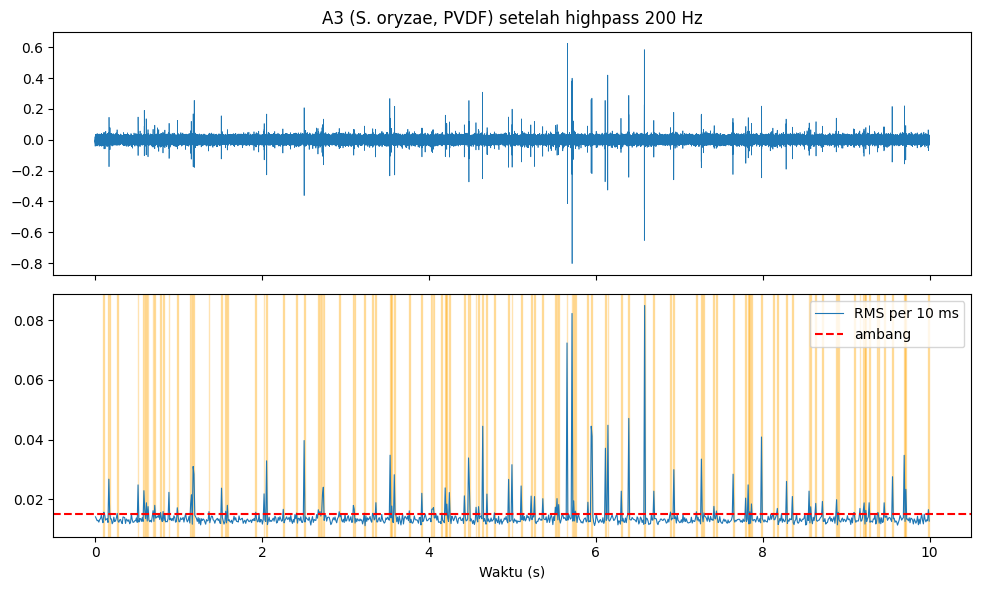

In [13]:
import matplotlib.pyplot as plt

y = highpass(load_resample("/content/bugbytes/A3-pvdfrw1.wav"), FS_TARGET)
r = rms_frames(y, FS_TARGET)
thr, s, e, dur, itv = detect_events(r)
print(f"{len(s)} event, ambang={thr:.5f}")
print("rata-rata durasi:", dur.mean() if len(dur) else None)

t = np.arange(len(y)) / FS_TARGET
tr = (np.arange(len(r)) + 0.5) * 0.01

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(t, y, lw=0.5)
ax[0].set_title("A3 (S. oryzae, PVDF) setelah highpass 200 Hz")
ax[1].plot(tr, r, lw=0.8, label="RMS per 10 ms")
ax[1].axhline(thr, color="r", ls="--", label="ambang")
for a, b in zip(s, e):
    ax[1].axvspan(a * 0.01, b * 0.01, color="orange", alpha=0.3)
ax[1].set_xlabel("Waktu (s)")
ax[1].legend()
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/proyek_kutu/plot_A3_event.png", dpi=150)
plt.show()

**Uji pipeline di satu file: A3 (S. oryzae, sensor PVDF)**
Hasil: 105 event dalam 10 detik, ambang 0,01518, durasi rata-rata 11,2 ms.
- Grafik atas: sinyal setelah highpass 200 Hz.
- Grafik bawah: RMS per 10 ms, garis ambang (merah putus-putus), dan event yang terdeteksi (oranye).
Pola klik pendek yang rapat sesuai karakter bunyi larva dalam gandum.

In [14]:
import numpy as np
frames = (dur / 0.01).round().astype(int)
print("jumlah event:", len(frames))
for n in [1, 2, 3]:
    print(f"event {n} frame ({n*10} ms):", (frames == n).sum())
print("event >= 4 frame:", (frames >= 4).sum())
print("durasi maks (ms):", dur.max() * 1000)
print("interval median (s):", np.median(itv))

jumlah event: 105
event 1 frame (10 ms): 94
event 2 frame (20 ms): 9
event 3 frame (30 ms): 2
event >= 4 frame: 0
durasi maks (ms): 30.0
interval median (s): 0.065


**Cek sebaran durasi event di A3**
Dari 105 event, 94 hanya 1 frame (10 ms), 9 event 2 frame, 2 event 3 frame, dan tidak ada yang 4 frame atau lebih. Durasi maksimal 30 ms dan jarak median antar event 65 ms. Jadi event berupa klik pendek, bukan getaran panjang. Durasi 10 ms artinya lebih pendek dari satu frame, bukan persis 10 ms.

In [15]:
import pandas as pd

files = [
 "A3-pvdfrw1.wav","A4-accelrw.wav","A5-w40khzrw1.wav","A6-w30khzrw1.wav","A7-piezorw1.wav",
 "A8-sz-lm3r1_f3-0s.wav","A9-sza-mar1f5-0s.wav",
 "A10-ptr-l-m4r2f4-2s.wav","A11-ptr_adu1-72s.wav",
 "I2-planeau2.wav","I3-monrbck1.wav","I4-monrbck2.wav",
]

hasil = []
for f in files:
    y = highpass(load_resample(f"/content/bugbytes/{f}"), FS_TARGET)
    r = rms_frames(y, FS_TARGET)
    thr, s, e, dur, itv = detect_events(r)
    hasil.append(dict(
        file=f,
        durasi_s=round(len(y)/FS_TARGET, 2),
        n_event=len(s),
        event_per_s=round(len(s)/(len(y)/FS_TARGET), 2),
        ambang=round(thr, 5),
        durasi_rata_ms=round(dur.mean()*1000, 1) if len(dur) else None,
        interval_median_s=round(float(np.median(itv)), 3) if len(itv) else None,
    ))

tabel = pd.DataFrame(hasil)
tabel.to_csv("/content/drive/MyDrive/proyek_kutu/hasil_event_minggu1.csv", index=False)
print(tabel.to_string())

                       file  durasi_s  n_event  event_per_s   ambang  durasi_rata_ms  interval_median_s
0            A3-pvdfrw1.wav     10.00      105        10.50  0.01518            11.2              0.065
1            A4-accelrw.wav     10.00      124        12.40  0.01631            11.9              0.050
2          A5-w40khzrw1.wav     10.00       46         4.60  0.04702            11.3              0.140
3          A6-w30khzrw1.wav     10.00       32         3.20  0.07890            10.3              0.290
4           A7-piezorw1.wav     10.00      105        10.50  0.02910            14.4              0.050
5     A8-sz-lm3r1_f3-0s.wav     20.91       80         3.83  0.04624            14.0              0.130
6      A9-sza-mar1f5-0s.wav     18.70      175         9.36  0.01317            18.0              0.055
7   A10-ptr-l-m4r2f4-2s.wav     18.59      148         7.96  0.00867            16.3              0.080
8      A11-ptr_adu1-72s.wav     21.04      124         5.89  0.0

**Pipeline dijalankan di 12 file**
5 file S. oryzae (A3 sampai A7), 2 S. zeamais (A8, A9), 2 P. truncatus (A10, A11), dan 3 file noise (I2, I3, I4). Hasil disimpan di hasil_event_minggu1.csv.

Temuan:
- S. oryzae (A3, A4, A7) konsisten sekitar 10 sampai 12 event per detik di tiga sensor berbeda.
- Sensor ultrasonik (A5, A6) lebih sedikit event (4,6 dan 3,2 per detik) karena fs 50 kHz diturunkan ke 20 kHz, sehingga komponen di atas 10 kHz hilang.
- S. zeamais dewasa (A9, 9,4 per detik) lebih ramai daripada larva (A8, 3,8 per detik).
- File noise juga menghasilkan event (I4: 6,07 per detik) karena ambang dihitung dari file itu sendiri. Jadi jumlah event saja tidak bisa membedakan hama dan noise. Itu sebabnya minggu 2 memakai campuran sinyal bersih + noise pada SNR terkendali.

In [16]:
import glob
for p in glob.glob("/content/drive/MyDrive/proyek_kutu/data/*"):
    print(p)

/content/drive/MyDrive/proyek_kutu/data/Insect-Pest-Sounds-inventory_1.csv
/content/drive/MyDrive/proyek_kutu/data/InsectSounds_2.zip
/content/drive/MyDrive/proyek_kutu/data/inventaris_fs.csv
/content/drive/MyDrive/proyek_kutu/data/Beetle_Vibration_Data_Key.txt
/content/drive/MyDrive/proyek_kutu/data/Beetle Vibration Data.csv


In [17]:
print(open("/content/drive/MyDrive/proyek_kutu/data/Beetle_Vibration_Data_Key.txt", encoding="utf-8", errors="ignore").read())

Beetle Vibration Column Descriptions
Trial: Identifies the trial block (A-U) in which each recording was conducted.
Species: Abbreviated scientific name for each beetle species
	R. dominica = Rhyzopertha dominica
	S. zeamais = Sitophilus zeamais
	T. castaneum = Tribolium castaneum
Density: The proportional density of insects in the grain mass (units = insects per kilogram). 
Av_Int: The mean interval (seconds) between vibration pulses 
Av_Dur: The mean duration (seconds) of each vibration pulse
Count: The total number of vibration pulses in each recording
Freq: The mean peak frequency (kHz) of each vibration pulse
ID: The individual name given to each observation
logInt: The log transformation of Av_Int
logCount: The log transformation of Count
logDur: The log transformation of Av_Dur
	



In [18]:
import pandas as pd
vib = pd.read_csv("/content/drive/MyDrive/proyek_kutu/data/Beetle Vibration Data.csv")
print(vib.shape)
print(vib.columns.tolist())
print(vib.head(10).to_string())

(159, 12)
['Unnamed: 0', 'Trial', 'Species', 'Density', 'Av_Int', 'Av_Dur', 'Count', 'Freq', 'ID', 'logInt', 'logCount', 'logDur']
   Unnamed: 0 Trial       Species  Density    Av_Int    Av_Dur  Count      Freq       ID    logInt  logCount    logDur
0           2     A   R. dominica       20  0.870756  0.001868     49  5.561719  A LGB 4 -0.060104  1.690196 -2.728679
1           3     A   R. dominica       40  0.001315  0.001572      6  5.390479  A LGB 8 -2.881006  0.778151 -2.803492
2           4     A  T. castaneum        5  0.116803  0.002825    208  5.380402  A RFB 1 -0.932548  2.318063 -2.548963
3           5     A  T. castaneum       20  0.163637  0.002128    849  4.313387  A RFB 4 -0.786119  2.928908 -2.671981
4           6     A  T. castaneum       40  0.125332  0.002267   1078  4.362691  A RFB 8 -0.901938  3.032619 -2.644619
5           7     A    S. zeamais        5  0.081106  0.002175    393  4.471455   A RW 1 -1.090947  2.594393 -2.662600
6           8     A    S. zeamais   

In [19]:
print(vib.groupby(["Species", "Density"]).size())
print(vib.groupby(["Species", "Density"])["Count"].median())

Species       Density
R. dominica   5          10
              20         16
              40         19
S. zeamais    5          16
              20         20
              40         19
T. castaneum  5          19
              20         20
              40         20
dtype: int64
Species       Density
R. dominica   5            16.0
              20           40.0
              40          116.0
S. zeamais    5            29.5
              20          160.0
              40          537.0
T. castaneum  5           661.0
              20         2245.0
              40         7204.5
Name: Count, dtype: float64


In [20]:
files = [
 "A3-pvdfrw1.wav","A4-accelrw.wav","A5-w40khzrw1.wav","A6-w30khzrw1.wav","A7-piezorw1.wav",
 "A8-sz-lm3r1_f3-0s.wav","A9-sza-mar1f5-0s.wav",
 "A10-ptr-l-m4r2f4-2s.wav","A11-ptr_adu1-72s.wav",
 "I2-planeau2.wav","I3-monrbck1.wav","I4-monrbck2.wav",
]

sel = pd.DataFrame({"file": files})
sel["File ID"] = sel.file.str.extract(r"^([A-Z])(\d+)").apply(lambda x: f"{x[0]}.{x[1]}", axis=1)
sel["peran"] = sel.file.str[0].map({"A": "hama gudang", "I": "noise"})

d = df.copy()
d["File ID"] = d["File ID"].str.strip()
sel = sel.merge(d[["File ID", "Description"]], on="File ID", how="left")
sel = sel.merge(inv[["file", "fs", "durasi_s"]], on="file", how="left")
sel = sel.rename(columns={"fs": "fs_asli"})
sel["fs_target"] = FS_TARGET

sel.to_csv("/content/drive/MyDrive/proyek_kutu/file_terpilih.csv", index=False)
print(sel[["file", "File ID", "peran", "fs_asli", "durasi_s", "fs_target"]].to_string())

                       file File ID        peran  fs_asli  durasi_s  fs_target
0            A3-pvdfrw1.wav     A.3  hama gudang    25000     10.00      20000
1            A4-accelrw.wav     A.4  hama gudang    25000     10.00      20000
2          A5-w40khzrw1.wav     A.5  hama gudang    50000     10.00      20000
3          A6-w30khzrw1.wav     A.6  hama gudang    50000     10.00      20000
4           A7-piezorw1.wav     A.7  hama gudang    25000     10.00      20000
5     A8-sz-lm3r1_f3-0s.wav     A.8  hama gudang    20000     20.91      20000
6      A9-sza-mar1f5-0s.wav     A.9  hama gudang    20000     18.70      20000
7   A10-ptr-l-m4r2f4-2s.wav    A.10  hama gudang    20000     18.59      20000
8      A11-ptr_adu1-72s.wav    A.11  hama gudang    20000     21.04      20000
9           I2-planeau2.wav     I.2        noise    25000     15.00      20000
10          I3-monrbck1.wav     I.3        noise    25000     15.00      20000
11          I4-monrbck2.wav     I.4        noise    

Simpan daftar file terpilih sebagai tabel